---
# Part 1. Regression — California Housing (35점)

**데이터셋:** `sklearn.datasets.fetch_california_housing()`  
**예측 목표:** 주택 중위 가격 (MedHouseVal)

> 이 파트에서는 Feature Selection → Linear Regression → Polynomial + Ridge 순서로 진행한다.


## 1-1. 데이터 준비 (7점)

아래 작업을 순서대로 수행하시오.

1. 데이터를 로드하고 DataFrame으로 변환하시오.
2. `shape`, `describe()`, 결측치 여부를 출력하시오.
3. train : test = **8 : 2** 로 분리하시오. (`random_state=42`)
4. `StandardScaler`를 적용하시오. (**주의: scaler는 train 데이터로만 `fit`할 것**)


In [36]:
# [1-1] 데이터 준비
# 필요한 라이브러리 import
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#1.데이터로드 및  데이터프레임 변환
housing = fetch_california_housing()
df = pd.DataFrame(housing.data, columns = housing.feature_names)
df['MedHouseVal']=housing.target

#2.shape,describe(), 결측치 여부 확인
print('shape', df.shape)
print(df.describe())
print('\n결측치 여부:')
print(df.isnull().sum())

#3.train : test = 8 : 2 로 분리
X =df.drop(columns ='MedHouseVal')
y= df['MedHouseVal']

X_train , X_test , y_train, y_test = train_test_split(X,y,test_size= 0.2, random_state =42)

#4.StandardScaler를 적용
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled =scaler.transform(X_test)

print('X_train shape: ', X_train_scaled.shape)
print('X_test shape:', X_test_scaled.shape)

shape (20640, 9)
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333333      3.000000   
25%        2.563400     18.000000      4.440716      1.006079    787.000000   
50%        3.534800     29.000000      5.229129      1.048780   1166.000000   
75%        4.743250     37.000000      6.052381      1.099526   1725.000000   
max       15.000100     52.000000    141.909091     34.066667  35682.000000   

           AveOccup      Latitude     Longitude   MedHouseVal  
count  20640.000000  20640.000000  20640.000000  20640.000000  
mean       3.070655     35.631861   -119.569704      2.068558  
std       10.386050      2.135952      2.003532      1.153956  
min        0.69

## 1-2. Feature Selection (8점)

**(1) [코딩 5점]** Pearson 상관계수를 계산하여 `MedHouseVal`과의 절댓값 기준 **상위 4개 feature**를 선택하고,  
선택된 feature만으로 새로운 train/test set을 구성하시오.

**(2) [서술 3점]** 아래 질문에 답하시오.
- 선택된 4개 feature는 무엇인가?
- 상관계수가 높다고 해서 반드시 좋은 feature라고 할 수 없는 경우를 한 가지 설명하시오.


In [38]:
# [1-2] Feature Selection
# 상관계수 계산 → 상위 4개 feature 선택

# 1. 상관계수 확인 
c = df.corr()['MedHouseVal'].drop('MedHouseVal')
print(c.sort_values(ascending=False))

# 상위 4개 feature 선택 
top4 = c.abs().sort_values(ascending=False)[:4].index.tolist()
print('\n선택된 상위 4개 feature:', top4)

# 선택된 feature로 새로운 train/test set 구성
X_train_selected = X_train_scaled[:, [housing.feature_names.index(f) for f in top4]]
X_test_selected  = X_test_scaled[:,  [housing.feature_names.index(f) for f in top4]]

print('\nX_train_selected shape:', X_train_selected.shape)
print('X_test_selected shape: ', X_test_selected.shape)



MedInc        0.688075
AveRooms      0.151948
HouseAge      0.105623
AveOccup     -0.023737
Population   -0.024650
Longitude    -0.045967
AveBedrms    -0.046701
Latitude     -0.144160
Name: MedHouseVal, dtype: float64

선택된 상위 4개 feature: ['MedInc', 'AveRooms', 'Latitude', 'HouseAge']

X_train_selected shape: (16512, 4)
X_test_selected shape:  (4128, 4)


✏️ **[서술형 답변란]** (2) Feature Selection 해석

>1)선택된 4개 feature :  MedInc(0.688075), AveRooms(0.151948), Latitude(-0.144160), HouseAge(0.105623)

>2)상관계수가 높다고 반드시 좋은 feature라고 할 수 없는 경우
>Pearson 상관계수는 선형 관계만 측정하며 상관관계가 인과관계를 의미하지 않는다. 예를 들어 Latitude(위도)는 집값에 직접적인 영향을 주지 않지만 캘리포니아에서는 위도가 낮은 남부 지역에 고가 도시가 밀집해 있어 상관계수가 높게 나온다. 이는 제3의 변수가 두 변수를 동시에 움직이는 관계이며 위도 자체는 집값의 원인이 아님에도 상관계수 순위에 오른 것이다. 따라서 상관계수만으로 feature를 선택하면 인과관계 없는 변수를 선택하는 오류가 생길 수 있다.

## 1-3. 모델 구현 (12점)

선택된 4개 feature를 사용하여 아래 세 모델을 순서대로 구현하시오.

| 단계 | 모델 | 설정 |
|------|------|------|
| ① | Linear Regression | 기본 설정 |
| ② | Polynomial Regression | `degree=2`, `PolynomialFeatures` 적용 후 LinearRegression |
| ③ | Ridge Regression | `degree=2` 다항 feature + `Ridge(alpha=10)` |

각 모델에 대해 **train score(R²)** 와 **test score(R²)** 를 출력하시오.

R² 설명: https://en.wikipedia.org/wiki/Coefficient_of_determination

```
출력 예시:
Linear      → Train R²: 0.6xx  |  Test R²: 0.6xx
Polynomial  → Train R²: 0.9xx  |  Test R²: -xxx.x   ← 과적합 확인
Ridge       → Train R²: 0.8xx  |  Test R²: 0.8xx
```


In [41]:
# [1-3-①] Linear Regression
from sklearn.linear_model import LinearRegression

lin = LinearRegression()
lin.fit(X_train_selected, y_train)
print(f'Linear -> Train R² : {lin.score(X_train_selected, y_train):.4f} | Test R² : {lin.score(X_test_selected, y_test):.4f}')

Linear -> Train R² : 0.5225 | Test R² : 0.5043


In [42]:
# [1-3-②] Polynomial Regression (degree=2)
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train_selected)
X_test_poly = poly.transform(X_test_selected)

pr = LinearRegression()
pr.fit(X_train_poly, y_train)

print(f'Polynomial -> Train R² : {pr.score(X_train_poly, y_train): .4f} | Test R² : {pr.score(X_test_poly,y_test):.4f}')

Polynomial -> Train R² :  0.5500 | Test R² : 0.5188


In [43]:
# [1-3-③] Ridge Regression (degree=2, alpha=10)
from sklearn.linear_model import Ridge

ri = Ridge(alpha=10)
ri.fit(X_train_poly, y_train)

print(f'Ridge -> Train R² : {ri.score(X_train_poly, y_train): .4f} | Test R² : {ri.score(X_test_poly,y_test):.4f}')

Ridge -> Train R² :  0.5500 | Test R² : 0.5188


## 1-4. 해석 및 분석 (8점)

**(1) [3점]** 세 모델의 train/test R² 점수를 비교하여, 과적합이 발생했는지 판단하고 **수치 근거**와 함께 설명하시오.

**(2) [3점]** Ridge가 과적합을 완화하는 원리를 수업에서 배운 **페널티 항(penalty term)** 개념을 사용하여 설명하시오.

**(3) [2점]** `alpha=10` 대신 다른 `alpha` 값을 설정하면 어떤 결과가 나오는지 실험을 하고, 그 결과를 설명하시오.


✏️ **[서술형 답변란]** (1) 과적합 판단

> Linear :     Train 0.5225 | Test 0.5043 → 차이 0.0182

> Polynomial : Train 0.5500 | Test 0.5188 → 차이 0.0312
> 
> Ridge :      Train 0.5500 | Test 0.5188 → 차이 0.0312

>세 모델 모두 Train-Test R² 차이가 0.03 이내로 과적합이 발생하지 않았다.

> 과적합이 발생하면 Train R²는 높고 Test R²는 크게 떨어진. 하지만 세 모델 모두 train과 test의 R²의 차이가 0.03이내로 매우 작다. Polynomial 과 Ridge에서 train R²가 Linear보다 약간 높아졌지만 test R²도 같이 높아진 것을 보면 과적합이 아니라는 것을 알 수 있다. 또한 feature를 상위 4개로 줄인 영향으로 전체적인 R² 점수가 낮게 나온 것을 알 수 있다.

✏️ **[서술형 답변란]** (2) Ridge 원리

> Ridge는 손실함수에 L2 페널티 항을 추가해 과적합을 억제한다. 수식으로 표현하면 다음과 같다. 

>J(θ) = E_mse(X, θ) + λ · (1/2) · Σθᵢ²

>기존 선형 회귀는 E_mse만 최소화하지만 Ridge는 여기에 계수 제곱합에 λ(=alpha)를 곱한 항을 더한다. 이 페널티 때문에 특정 계수가 지나치게 커지면 손실값 자체가 올라가므로 모델은 훈련 데이터를 완벽히 맞추지 않고 계수를 작게 하는 방향으로 학습된다. alpha=0이면 페널티가 없어 일반 선형회귀와 같고 alpha가 커질수록 계수가 0에 가까워져 모델이 단순해진다.

In [47]:
# alpha 값 변화에 따른 Ridge 모델의 성능 변화 실험 코드
alpha_values = [0.001, 0.01, 1, 10, 100, 1000]

for a in alpha_values:
    ri = Ridge(alpha=a)
    ri.fit(X_train_poly, y_train)
    print(f'alpha={a:<6} Train R² : {ri.score(X_train_poly, y_train):.4f}  |  Test R² : {ri.score(X_test_poly, y_test):.4f}')

alpha=0.001  Train R² : 0.5500  |  Test R² : 0.5188
alpha=0.01   Train R² : 0.5500  |  Test R² : 0.5188
alpha=1      Train R² : 0.5500  |  Test R² : 0.5188
alpha=10     Train R² : 0.5500  |  Test R² : 0.5188
alpha=100    Train R² : 0.5499  |  Test R² : 0.5187
alpha=1000   Train R² : 0.5434  |  Test R² : 0.5129


✏️ **[서술형 답변란]** (3) alpha 값 변화에 따른 모델 성능 결과 분석

> alpha=0.001~10 구간에서는 Train/Test R² 모두 0.5500/0.5188로 변화가 없었고 alpha=1000에서 Train 0.5434 / Test 0.5129로 약간 감소했다.

>작은 alpha에서 성능 변화가 없는 이유는 이 데이터는 이미 StandardScaler로 정규화되어 있고 feature가 4개로 적어 계수 자체가 크지 않기 떄문이다. 따라서 alpha가 0.001~10 수준에서는 페널티가 영향이 거의 없어서 일반 선형회귀와 비슷하다.
>alpha=1000에서 성능이 하락한 이유는 페널티가 과하게 강해져 모든 계수가 0에 가까워지면서 모델이 지나치게 단순해지는 과소적합이 발생했기 때문이다.

>따라서 이 데이터에서는 alpha=10 전후가 적절한 정규화 수준임을 확인할 수 있다.

---
# Part 2. Classification — Breast Cancer (50점)

**데이터셋:** `sklearn.datasets.load_breast_cancer()`  
**예측 목표:** 악성(0) / 양성(1) 종양 분류

> 이 파트에서는 KNN → SVM → Decision Tree 순서로 구현하고 비교한다.


## 2-1. 데이터 준비 (5점)

아래 작업을 수행하시오.

1. 데이터를 로드하고 DataFrame으로 변환하시오.
2. `shape`, `describe()`, 클래스 분포(`value_counts`)를 출력하시오.
3. train : test = **7 : 3** 으로 분리하시오. (`random_state=42`)
4. `StandardScaler`를 적용하시오. (train으로만 `fit`)


In [51]:
# [2-1] 데이터 준비
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

#1.데이터 로드 및 DataFrame 변환
cancer = load_breast_cancer()
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df['target'] = cancer.target

#2.shape,describe(),클래스 분포 출력
print('shape:',df.shape)
print(df.describe())
print(df['target'].value_counts())

#3. train : test = 7 : 3 분리
X_train, X_test, y_train, y_test = train_test_split(cancer.data, cancer.target, test_size=0.3, random_state=42)

#4.StandardScaler 적용
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled =scaler.transform(X_test)

print('\ntrain shape : ', X_train_scaled.shape)
print('test shape : ', X_test_scaled.shape)

shape: (569, 31)
       mean radius  mean texture  mean perimeter    mean area  \
count   569.000000    569.000000      569.000000   569.000000   
mean     14.127292     19.289649       91.969033   654.889104   
std       3.524049      4.301036       24.298981   351.914129   
min       6.981000      9.710000       43.790000   143.500000   
25%      11.700000     16.170000       75.170000   420.300000   
50%      13.370000     18.840000       86.240000   551.100000   
75%      15.780000     21.800000      104.100000   782.700000   
max      28.110000     39.280000      188.500000  2501.000000   

       mean smoothness  mean compactness  mean concavity  mean concave points  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.104341        0.088799             0.048919   
std           0.014064          0.052813        0.079720             0.038803   
min           0.052630          0.019380        0.000000             0.00

## 2-2. KNN (K-Nearest Neighbors) (13점)

**(1) [6점]** k = 1, 3, 5, 7, 9, 11, 13, 15 에 대해 각각 KNN 모델을 학습하고,  
train accuracy와 test accuracy를 계산한 뒤 **그래프로 시각화**하시오.

**(2) [3점]** 그래프를 바탕으로 **최적의 k 값**을 선택하고, 선택 근거를 설명하시오.  
(힌트: 과적합/underfitting 관점에서 서술)

**(3) [4점]** 아래 질문에 답하시오.
- k가 너무 작을 때(예: k=1) 어떤 문제가 발생하는가?
- k가 너무 클 때 어떤 문제가 발생하는가?
- KNN에서 `StandardScaler`를 반드시 적용해야 하는 이유는 무엇인가?


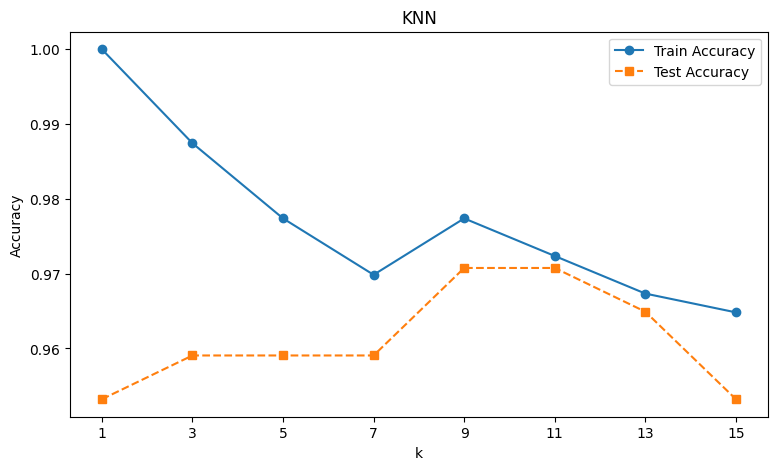

k= 1 | Train: 1.0000 | Test: 0.9532
k= 3 | Train: 0.9874 | Test: 0.9591
k= 5 | Train: 0.9774 | Test: 0.9591
k= 7 | Train: 0.9698 | Test: 0.9591
k= 9 | Train: 0.9774 | Test: 0.9708
k=11 | Train: 0.9724 | Test: 0.9708
k=13 | Train: 0.9673 | Test: 0.9649
k=15 | Train: 0.9648 | Test: 0.9532


In [53]:
# [2-2-①] KNN - k 값별 accuracy 계산 및 시각화
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

k_list = [1, 3, 5, 7, 9, 11, 13, 15]
train_scores = []
test_scores = []

for k in k_list:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    train_scores.append(accuracy_score(y_train, knn.predict(X_train_scaled)))
    test_scores.append(accuracy_score(y_test, knn.predict(X_test_scaled)))

plt.figure(figsize=(9, 5))
plt.plot(k_list, train_scores, 'o-', label='Train Accuracy')
plt.plot(k_list, test_scores, 's--', label='Test Accuracy')
plt.xlabel('k')
plt.ylabel('Accuracy')
plt.title('KNN')
plt.xticks(k_list)
plt.legend()
plt.show()

for k, tr, te in zip(k_list, train_scores, test_scores):
    print(f'k={k:2d} | Train: {tr:.4f} | Test: {te:.4f}')

✏️ **[서술형 답변란]** (2) 최적 k 선택 근거

> 최적의 k값은 k=9이다.

>k=1일 때 Train Accuracy가 1.0000이지만 Test Accuracy는 0.9532로 가장 낮다. 훈련 데이터에만 과하게 맞춰진 과적합 상태라 새로운 데이터에는 약해진다.
k가 증가할수록 Test Accuracy가 올라가다가 k=9에서 0.9708로 가장 큰 값을 확인할 수 있다. 이후 k=13,15로 넘어가면 Train 과 Test 모두 떨어지기 시작하는데 이웃을 너무 많이 참고하면서 경계가 지나치게 단순해지는 과소적합이 나타난다.

>따라서 Train Accuracy와 Test Accuracy의 차이가 적으면서 전체적인 정확도가 높게 유지되는 k=9가 최적이라고 생각한다.

✏️ **[서술형 답변란]** (3) KNN 원리 해석

> k가 너무 작을 때 (k=1)
k=1이면 가장 가까운 1개만 보고 분류하기 때문에 훈련 데이터의 노이즈나 이상치에 민감하게 반응한다. 따라서 결정 경계가 복잡해지는 과적합이 발생해 새로운 데이터에는 제대로 된 예측이 어려워진다. k=1일때 Train은 1.0000이지만 Test가 0.9532로 가장 낮은 값이 나온 것으로 이를 확인 할 수 있다.

>k가 너무 클 때
k가 너무 크면 거리상 멀리 있는 관계없는 데이터까지 이웃으로 포함하게 되기 때문에 어떤 데이터가 들어와도 비슷한 결과를 내는 모델이 될 수 있다. 그 결과 과소적합이 발생한다. k=15일 때 Train  0.9648, Test 0.9532로 k=9와 비교했을 때 Test Accuracy가 0.0176 떨어진 것으로 이를 확인 할 수 있다.

>StandardScaler를 반드시 적용해야 하는 이유
KNN은 거리 기반으로 이웃을 찾는다. feature마다 단위가 다르면 값이 큰 feature가 거리 계산을 결정해버린다. 스케일링으로 모든 피처를 같은 기준으로 맞춰야 각 feature가 제대로 반영된 거리 계산을 할 수 있으므로 StandardScaler를 반드시 적용해야 한다.

## 2-3. SVM (Support Vector Machine) (14점)

**(1) [8점]** `Pipeline`을 사용하여 아래와 같이 SVM 모델을 구현하고 test accuracy를 출력하시오.

```python
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

svm = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', LinearSVC(C=1, loss='hinge', max_iter=10000))
])
```

이후 C = 0.01, 0.1, 1, 10, 100 으로 변경하며 train/test accuracy를 계산하고 **그래프로 시각화**하시오.

**(2) [6점]** 아래 질문에 답하시오.
- SVM에서 **마진(margin)** 과 **서포트 벡터(support vector)** 의 의미를 설명하시오.
- C 값이 커질수록 모델에 어떤 변화가 생기는가? 본인의 실험 결과와 연결하여 설명하시오.



Test Accuracy: 0.9766


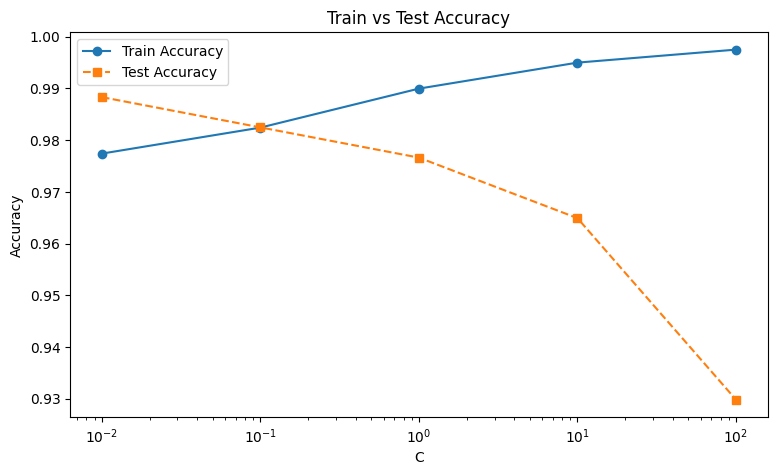

C= 0.01 | Train: 0.9774 | Test: 0.9883
C=  0.1 | Train: 0.9824 | Test: 0.9825
C=    1 | Train: 0.9899 | Test: 0.9766
C=   10 | Train: 0.9950 | Test: 0.9649
C=  100 | Train: 0.9975 | Test: 0.9298


In [57]:
# [2-3-①] SVM - Pipeline 구현 및 C 값 실험
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# 기본 모델 (C=1)
svm = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', LinearSVC(C=1, loss='hinge', max_iter=10000))
])

# Pipeline이 내부에서 스케일링 수행
svm.fit(X_train, y_train)
print(f"Test Accuracy: {accuracy_score(y_test, svm.predict(X_test)):.4f}")

# C 값 변경 실험
C_values = [0.01, 0.1, 1, 10, 100]
train_scores = []
test_scores = []

for C in C_values:
    model = Pipeline([('scaler', StandardScaler()),
                      ('svc', LinearSVC(C=C, loss='hinge', max_iter=10000))])
    model.fit(X_train, y_train)
    train_scores.append(accuracy_score(y_train, model.predict(X_train)))
    test_scores.append(accuracy_score(y_test, model.predict(X_test)))

# 시각화
plt.figure(figsize=(9, 5))
plt.plot(C_values, train_scores, 'o-', label='Train Accuracy')
plt.plot(C_values, test_scores, 's--', label='Test Accuracy')
plt.xscale('log')
plt.xlabel('C')
plt.ylabel('Accuracy')
plt.title('Train vs Test Accuracy')
plt.legend()
plt.show()

for C, tr, te in zip(C_values, train_scores, test_scores):
    print(f'C={C:5} | Train: {tr:.4f} | Test: {te:.4f}')

✏️ **[서술형 답변란]** (2) SVM 원리 해석

> margin과 support vector의 의미 : 결정 경계 바로 근처에 위치한 데이터 포인트들을 서포트 벡터라고 한다. 마진은 두 클래스의 서포트 벡터들 사이의 거리이다. SVM은 이 마진을 최대한 크게 만드는 결정 경계를 찾는 게 중요하다. 마진이 넓을수록 두 클래스가 명확하게 구분되기 때문에 새로운 데이터가 들어와도 안정적으로 분류가 가능하다. 

> C 값이 커질수록 모델의 변화 : C는 분류 오류에 대한 패널티를 조절하는 하이퍼파라미터다. C가 클수록 정확하게 분류하려고 하기 때문에 마진이 좁아지고 결정 경계가 훈련 데이터에 맞춰 복잡해진다.
 
>실험 결과에서 C가 0.01에서 100으로 증가할수록 Train Accuracy는 0.9774에서 0.9975로 계속 증가 하지만 Test Accuracy는 0.9883에서 0.9298로 감소한다. 이는 C가 커질수록 훈련 데이터에는 잘 맞지만 새로운 데이터에는 일반화되지 못하는 과적합이 발생한다는 것을 알 수 있다. 또한 C가 0.01일때 Test Accuracy 0.9883으로 가장 높아 안정적인 일반화 성능임을 알 수 있다.

## 2-4. Decision Tree (13점)

**(1) [6점]** 아래 두 기준으로 각각 Decision Tree를 학습하고 test accuracy를 비교하시오.

```python
from sklearn.tree import DecisionTreeClassifier

clf_gini    = DecisionTreeClassifier(criterion="gini",    max_depth=5, min_samples_leaf=3, random_state=42)
clf_entropy = DecisionTreeClassifier(criterion="entropy", max_depth=5, min_samples_leaf=3, random_state=42)
```

각 모델에 대해 `classification_report`를 출력하고, `tree.plot_tree()`로 트리를 시각화하시오.

**(2) [4점]** 아래 질문에 답하시오.
- **Gini impurity** 와 **Entropy** 의 차이를 설명하시오.
- 두 기준의 결과를 비교하고, 어떤 기준이 이 데이터에 더 적합한지 수치 근거와 함께 설명하시오.

**(3) [3점]** `max_depth=5`, `min_samples_leaf=3` 으로 설정된 상태에서 `max_depth=None` 등 설정을 변경하면 어떤 결과가 나오는지 실험하고 해석하시오.


Gini
Test Accuracy: 0.9649
              precision    recall  f1-score   support

   malignant       0.95      0.95      0.95        63
      benign       0.97      0.97      0.97       108

    accuracy                           0.96       171
   macro avg       0.96      0.96      0.96       171
weighted avg       0.96      0.96      0.96       171

Entropy
Test Accuracy: 0.9766
              precision    recall  f1-score   support

   malignant       0.98      0.95      0.97        63
      benign       0.97      0.99      0.98       108

    accuracy                           0.98       171
   macro avg       0.98      0.97      0.97       171
weighted avg       0.98      0.98      0.98       171



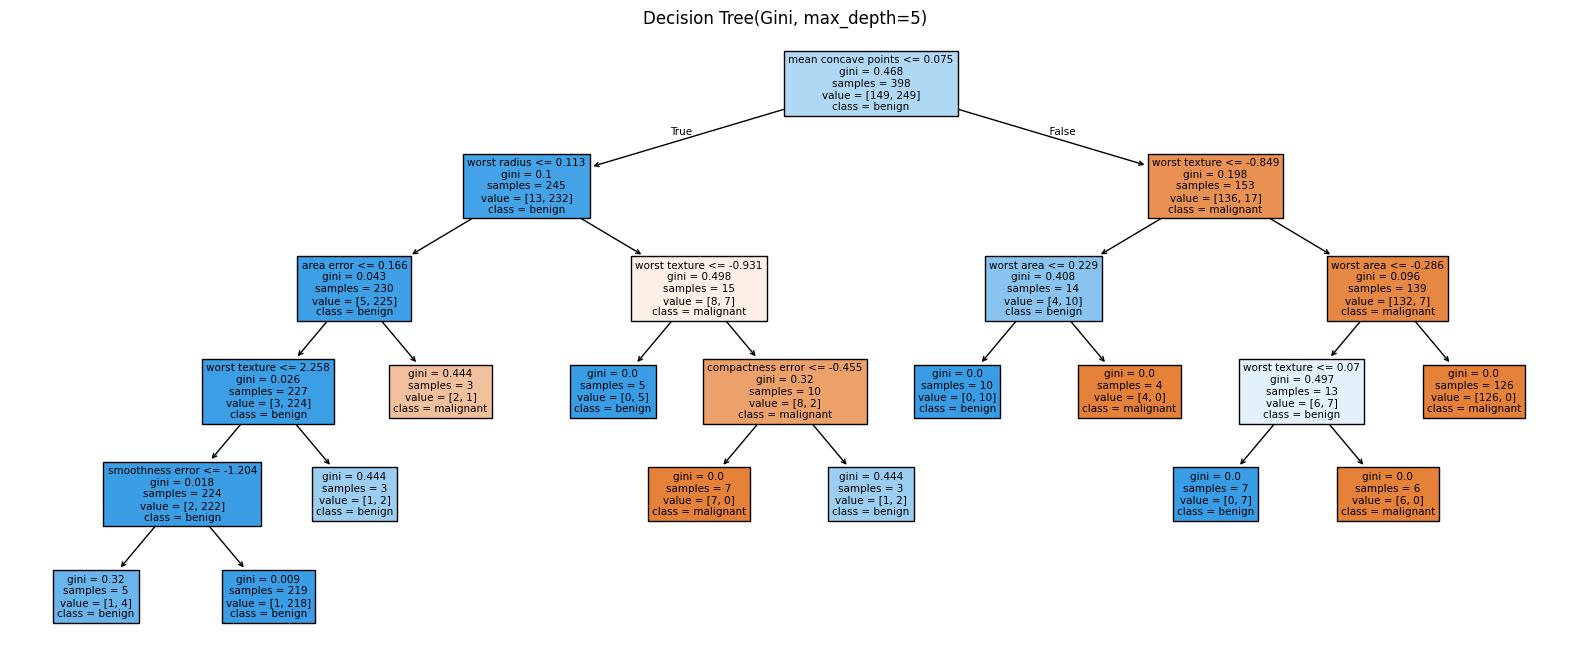

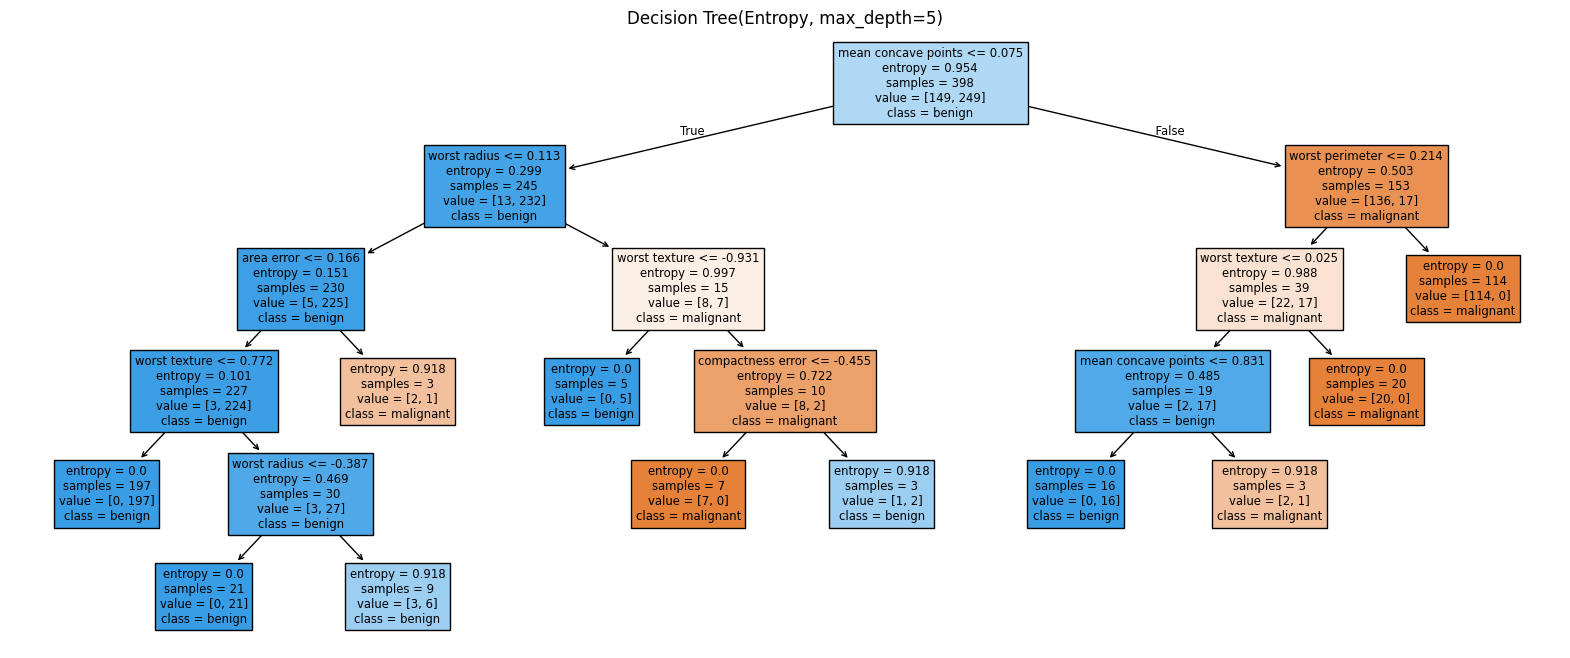

In [60]:
# [2-4-①] Decision Tree — gini vs entropy 비교
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, accuracy_score
import matplotlib.pyplot as plt

# 모델 정의
clf_gini = DecisionTreeClassifier(criterion="gini", max_depth=5,
                                  min_samples_leaf=3, random_state=42)
clf_entropy = DecisionTreeClassifier(criterion="entropy", max_depth=5, 
                                     min_samples_leaf=3, random_state=42)

# 학습
clf_gini.fit(X_train_scaled, y_train)
clf_entropy.fit(X_train_scaled, y_train)

# classification_report 출력
print("Gini")
print(f"Test Accuracy: {accuracy_score(y_test, clf_gini.predict(X_test_scaled)):.4f}")
print(classification_report(y_test, clf_gini.predict(X_test_scaled), target_names=['malignant', 'benign']))

print("Entropy")
print(f"Test Accuracy: {accuracy_score(y_test, clf_entropy.predict(X_test_scaled)):.4f}")
print(classification_report(y_test, clf_entropy.predict(X_test_scaled), target_names=['malignant', 'benign']))

# 트리 시각화 - Gini
plt.figure(figsize=(20, 8))
plot_tree(clf_gini, filled=True, feature_names=cancer.feature_names, class_names=['malignant', 'benign'])
plt.title("Decision Tree(Gini, max_depth=5)")
plt.show()

# 트리 시각화 - Entropy
plt.figure(figsize=(20, 8))
plot_tree(clf_entropy, filled=True, feature_names=cancer.feature_names, class_names=['malignant', 'benign'])
plt.title("Decision Tree(Entropy, max_depth=5)")
plt.show()

✏️ **[서술형 답변란]** (2) Gini vs Entropy 해석

> Gini Impurity와 Entropy의 차이
두 기준 모두 노드의 불순도를 측정해 분기 기준을 결정한다.
Gini는 각 클래스 확률의 제곱합을 1에서 뺀 값으로 계산하며 로그 연산이 없어 계산이 빠르다.
Entropy는 각 클래스 확률에 로그를 취한 값의 가중합으로 계산하며 불순도 변화에 더 민감하게 반응한다.

> 결과 비교 및 적합한 기준 선택
Test Accuracy는 Entropy(0.9766)가 Gini(0.9649)보다 높다. 유방암 진단에서 악성을 놓치는 FN이 치명적이므로 malignant recall이 중요한 지표인데 두 기준 모두 0.95로 같다. precision은 Gini 0.95, Entropy 0.98로 차이가 있고 f1-score도 Entropy(0.97)가 더 높다. 따라서 수치와 특성 모두 고려할 때 이 데이터에는 Entropy가 더 적합하다.

In [62]:
# 여기에 max_depth, min_samples_leaf 등 값 변화하며 모델 성능을 비교하는 코드 작성
# max_depth=None으로 변경 실험
# max_depth 변화 실험 (Gini & Entropy)
print("max_depth 변화 실험 (min_samples_leaf=3 고정) ")
for depth in [3, 5, 7, 10, None]:
    for crit in ["gini", "entropy"]:
        clf = DecisionTreeClassifier(criterion=crit, max_depth=depth, min_samples_leaf=3, random_state=42)
        clf.fit(X_train_scaled, y_train)
        print(f"depth={str(depth):<5} [{crit}] Train: {accuracy_score(y_train, clf.predict(X_train_scaled)):.4f} | Test: {accuracy_score(y_test, clf.predict(X_test_scaled)):.4f}")
    print()

# min_samples_leaf 변화 실험 (Gini & Entropy)
print("min_samples_leaf 변화 실험 (max_depth=5 고정) =")
for leaf in [1, 3, 10, 20]:
    for crit in ["gini", "entropy"]:
        clf = DecisionTreeClassifier(criterion=crit, max_depth=5, min_samples_leaf=leaf, random_state=42)
        clf.fit(X_train_scaled, y_train)
        print(f"leaf={leaf:<3} [{crit}] Train: {accuracy_score(y_train, clf.predict(X_train_scaled)):.4f} | Test: {accuracy_score(y_test, clf.predict(X_test_scaled)):.4f}")
    print()

max_depth 변화 실험 (min_samples_leaf=3 고정) 
depth=3     [gini] Train: 0.9698 | Test: 0.9649
depth=3     [entropy] Train: 0.9799 | Test: 0.9708

depth=5     [gini] Train: 0.9874 | Test: 0.9649
depth=5     [entropy] Train: 0.9849 | Test: 0.9766

depth=7     [gini] Train: 0.9874 | Test: 0.9532
depth=7     [entropy] Train: 0.9899 | Test: 0.9532

depth=10    [gini] Train: 0.9874 | Test: 0.9532
depth=10    [entropy] Train: 0.9899 | Test: 0.9532

depth=None  [gini] Train: 0.9874 | Test: 0.9532
depth=None  [entropy] Train: 0.9899 | Test: 0.9532

min_samples_leaf 변화 실험 (max_depth=5 고정) =
leaf=1   [gini] Train: 0.9950 | Test: 0.9532
leaf=1   [entropy] Train: 0.9925 | Test: 0.9532

leaf=3   [gini] Train: 0.9874 | Test: 0.9649
leaf=3   [entropy] Train: 0.9849 | Test: 0.9766

leaf=10  [gini] Train: 0.9447 | Test: 0.9415
leaf=10  [entropy] Train: 0.9648 | Test: 0.9649

leaf=20  [gini] Train: 0.9246 | Test: 0.8947
leaf=20  [entropy] Train: 0.9246 | Test: 0.8947



✏️ **[서술형 답변란]** (3) max_depth, min_samples_leaf 설정 근거

>max_depth 실험 결과 depth=5에서 Entropy 기준 Test Accuracy 0.9766으로 가장 높았다. depth=7 이상부터는 두 기준 모두 Test 0.9532로 감소하고 Train은 유지되어 과적합이 발생한 것을 확인할 수 있다. depth=None도 마찬가지로 Test 0.9532이므로 트리를 훨씬 깊게 해도 성능 개선이 없고 일반화 성능이 떨어진다.

>min_samples_leaf 실험 결과 leaf=1일 때 Gini Train 0.9950 / Test 0.9532, Entropy Train 0.9925 / Test 0.9532로 Train과 Test 차이가 크게 벌어지는 과적합이 나타났다. leaf=3에서 Gini Test 0.9649, Entropy Test 0.9766으로 가장 높은 일반화 성능을 보였고 leaf=10부터는 Test가 0.9415 이하로 감소하며 leaf=20에서는 두 기준 모두 Test 0.8947로 심한 과소적합이 발생했다.

>따라서 max_depth=5, min_samples_leaf=3이 두 실험 모두에서 Train/Test 균형과 Test Accuracy가 가장 적합한 설정임을 수치로 알 수 있다.

## 2-5. 성능 분석 및 모델 비교 (5점)

**(1) [2점]** 최적 k의 KNN, C=1의 SVM, gini DT 세 모델의 test accuracy를 하나의 표로 정리하시오.

**(2) [3점]** 아래 질문에 답하시오.
- 이 데이터(유방암 진단)에서 **False Negative(FN)** 와 **False Positive(FP)** 중 어느 쪽이 더 위험한가?  
  이유를 의학적 관점에서 설명하시오.
- Accuracy 하나만으로 모델 성능을 판단하는 것이 부적절한 이유를 설명하시오.


>문제 조건(C=1)을 따르지만 실험상 최적은 C=0.01과 Entropy dt임을 확인하였음

In [66]:
# [2-5-①] 세 모델 성능 비교 표
# 여기에 코드를 작성하시오
results = {
    'KNN (k=9)': accuracy_score(y_test, KNeighborsClassifier(n_neighbors=9).fit(X_train_scaled, y_train).predict(X_test_scaled)),
    'SVM (C=1)': accuracy_score(y_test, Pipeline([('scaler', StandardScaler()), ('svc', LinearSVC(C=1, loss='hinge', max_iter=10000))]).fit(X_train, y_train).predict(X_test)),
    'Decision Tree (Gini)': accuracy_score(y_test, clf_gini.predict(X_test_scaled))}

print(f"{'Model':<25} {'Test Accuracy'}")
print("-" * 40)
for model, acc in results.items():
    print(f"{model:<25} {acc:.4f}")


Model                     Test Accuracy
----------------------------------------
KNN (k=9)                 0.9708
SVM (C=1)                 0.9766
Decision Tree (Gini)      0.9649


✏️ **[서술형 답변란]** (2) FN/FP 해석 및 Accuracy 한계

>  False Negative(FN)와 False Positive(FP) 중 더 위험한 것
> FP는 실제로 정상인데 암이라고 잘못 분류하는 경우이다. 불필요한 추가 검사나 치료로 이어질 수 있지만 재검사를 통해 바로 잡을 수 있기 때문에 심각한 문제가 되지 않는다. FN은 실제로 암인데 정상이라고 잘못 분류하는 경우이다. 이는 환자가 암 진단을 받지 못하여 치료 시기를 놓치게 만든다. 암은 초기에 발견할수록 생존율이 높아지기 때문에 FN으로 인해 치료 시기를 놓치면 생명에 직접적으로 영향을 끼칠 수 있다. 따라서 FP보다 FN이 훨씬 더 위험하다. 

> Accuracy 하나만으로 모델 성능을 판단하는 것이 부적절한 이유
이 데이터셋은 전체 569개 중 악성 212개(37%), 양성 357개(63%)로 클래스 불균형이 존재한다. 모델이 모든 샘플을 양성으로만 예측해도 Accuracy는 약 63%가 나오는데 이 경우 악성을 하나도 잡지 못한 모델임에도 수치상으로는 나쁘지 않게 보인다. 유방암처럼 FN이 치명적인 상황에서는 이러한 Accuracy만 보면 악성 종양을 잡지 못할 수 있기 때문에 단독 지표로 사용하기에 부적절하다. 이러한 상황에서는 악성을 얼마나 놓치지 않기 위해 Recall, Precision, F1-score 등 다양한 지표를 종합적으로 고려해야 한다.

---
# Part 3. 종합 분석 (15점)


## 3-1. Regression vs Classification 비교 (5점)

**(1) [2점]** Regression과 Classification의 근본적인 차이를 아래 두 관점에서 설명하시오.
- 예측값(output)의 형태
- 주요 평가지표

**(2) [3점]** California Housing 데이터의 `MedHouseVal`을 기준으로  
"고가(상위 50%) / 저가(하위 50%)" 로 이진 분류 문제로 변환한다고 가정하자.  
이렇게 문제를 변환할 때의 **장점 1가지**와 **단점 1가지**를 구체적으로 서술하시오.


✏️ **[서술형 답변란]** (1) Regression vs Classification

>예측값의 형태: Regression은 주택 가격, 매출액처럼 연속적인 수치를 예측한다. Classification은 악성/양성, 스팸/정상처럼 이산적인 클래스 레이블을 예측한다. 

>주요 평가지표 : Regression은 예측값과 실제값의 차이를 측정하는 MSE, RMSE, R² 등을 사용한다. Classification은 예측한 클래스가 얼마나 정확한지를 측정하는 Accuracy, Precision, Recall, F1-score등을 사용한다. 

✏️ **[서술형 답변란]** (2) 문제 변환 장단점

> 장점: 회귀 문제는 연속적인 수치를 정확하게 예측해야 하기 때문에 모델이 복잡해지고 MSE같은 오차 지표를 직관적으로 해석하기 어렵다. 하지만 이진 분류는 변환하면 고가와 저가 두 클래스 중 하나를 맞추는 문제가 되어 모델이 단순해지고 분류 지표로 성능을 명확하게 평가할 수 있다.

> 단점 : MedHouseVal의 실제 수치 정보가 사라진다. 중앙값을 기준으로 나누기 때문에 중앙값보다 아주 조금 높은 집과 아주 조금 낮은 집이 완전히 다른 클래스로 분류된다. 이처럼 연속적인 데이터를 임의의 기준으로 이진화하면 정보가 손실되며 부동산 가격 산정처럼 실제로 집값이 얼마인지 알아야하는 상황에서는 분류 결과만으로 충분한 정보를 제공하지 못한다.

## 3-2. 최적 모델 선택 (5점)

KNN, SVM, Decision Tree 중 **Breast Cancer 진단에 가장 적합한 모델**을 선택하고,  
아래 세 가지 관점을 모두 포함하여 근거를 서술하시오.

- **성능 (Accuracy, FN 관점)**
- **해석 가능성 (의사/환자에게 설명 가능한가)**
- **일반화 (새로운 환자 데이터에 대한 신뢰도)**


✏️ **[서술형 답변란]** 최적 모델 선택 및 근거

>세 모델 중 SVM이 Breast Cancer 진단에 가장 적합하다고 생각한다.

>Test Accuracy 기준으로 SVM(C=1,0.9766) > KNN(k=9, 0.9708) > Decision Tree(Gini, 0.9649)이다. KNN은 k값에 따라 성능 변동이 크고 경계 근처 샘플에서 결과가 바뀌기 때문에 악성 샘플이 경계 근처에 위치할 경우 FN이 증가할 위험이 있다. Decision Tree는 max_depth를 제한하지 않으면 과적합이 심하게 발생하며 훈련 데이터에 없던 패턴의 악성 샘플을 놓치는 FN이 발생할 수 있다. 하지만 SVM은 마진을 최대화하는 방식으로 결정 경계를 잡기 때문에 경계 근처의 애매한 샘플도 잘 분류할 수 있어 FN 또한 최소화 할 수 있다.

> 해석 가능성은 Decision Tree가 가장 적합하다. 트리 그림으로 어떤 feature 기준으로 갈렸는지 바로 보이기 때문에 의사나 환자한테 설명하기 편하다. 하지만 진단 모델에서 해석 가능성보다 악성을 얼마나 안 놓치냐가 더 우선이라고 생각해서 SVM을 선택했다.

> 일반화 관점에서 KNN이 새 데이터마다 전체 훈련 데이터와 거리를 다시 비교해야 해서 분포가 조금만 달라져도 성능이 불안정하고 Decision Tree는 제약이 없으면 과적합된다. SVM은 C값을 낮게 유지하면 넓은 마진을 확보해 새로운 데이터에도 안정적으로 작동할 것이다.


## 3-3. 실무 적용 시 고려사항 (5점)

성능이 높은 모델이라도 실제 병원에 도입하기 어려운 이유가 있다.  
아래 두 관점에서 각각 구체적인 문제점을 1가지씩 서술하시오.

- **기술적 관점** (예: 데이터 품질, 모델 업데이트, 편향 등)
- **윤리·법적 관점** (예: 오진 책임, 개인정보, 설명 의무 등)


✏️ **[서술형 답변란]** 기술적 관점

> 데이터 편향 문제가 있다. 이 모델은 특정 병원이나 특정 시기에 수집된 데이터로 학습되었기 때문에 다른 병원이나 다른 인구집단에서 수집한 환자 데이터에는 성능이 떨어질 수 있다. 실험실 수치의 측정 장비나 기준이 병원마다 다를 수도 있어서 훈련 데이터와 분포가 다른 새로운 데이터가 들어오면 모델이 제대로 작동하지 않는 데이터 분포 이동문제가 발생 할 수 있다.

✏️ **[서술형 답변란]** 윤리·법적 관점

> 윤리/법적으로는 오진 책임 문제가 핵심이다. SVM은 왜 그런 판단을 내렸는지 설명이 안 된다. 악성으로 분류했는데 틀렸을 때 또는 양성으로 놓쳤을 때 그 책임이 모델인지 의사인지 불분명해진다. 환자는 자신의 진단 근거를 설명받을 권리가 있고 이 부분이 해결되지 않으면 성능과 무관하게 실제 도입은 어렵다.

---
## Part 1 추가분석 

* Part 1에서는 train/test R² 점수가 0.5내외로 성능이 좋은 모델을 구현하지 못하였다.
* 회귀분석의 목적은 변수들 사이의 관계를 수학적 모델로 설명하고 이를 바탕으로 미래값을 예측하는 것이다. 추가분석을 통해 fetch_california_housing 데이터 셋에서 예측 성능이 좋은 모델을 구현하는것을 목표로 모델링을 수행해보고자 한다.

In [78]:
import subprocess, sys
pkgs = ['seaborn', 'xgboost', 'statsmodels']
for p in pkgs:
    subprocess.run([sys.executable, '-m', 'pip', 'install', p, '-q'], check=True)

In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
plt.rcParams['axes.unicode_minus'] = False

from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
import xgboost as xgb
from sklearn.model_selection import GridSearchCV

In [80]:
# 데이터 로드
housing = fetch_california_housing()
df_raw = pd.DataFrame(housing.data, columns=housing.feature_names)
df_raw['MedHouseVal'] = housing.target

### 1.EDA 

#### 1-1 기초 통계 및 분포

In [82]:
display(df_raw.describe().round(2))

print('\n왜도확인')
skew = df_raw.skew().sort_values(ascending=False)
print(skew.round(3))

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00



왜도확인
AveOccup       97.640
AveBedrms      31.317
AveRooms       20.698
Population      4.936
MedInc          1.647
MedHouseVal     0.978
Latitude        0.466
HouseAge        0.060
Longitude      -0.298
dtype: float64


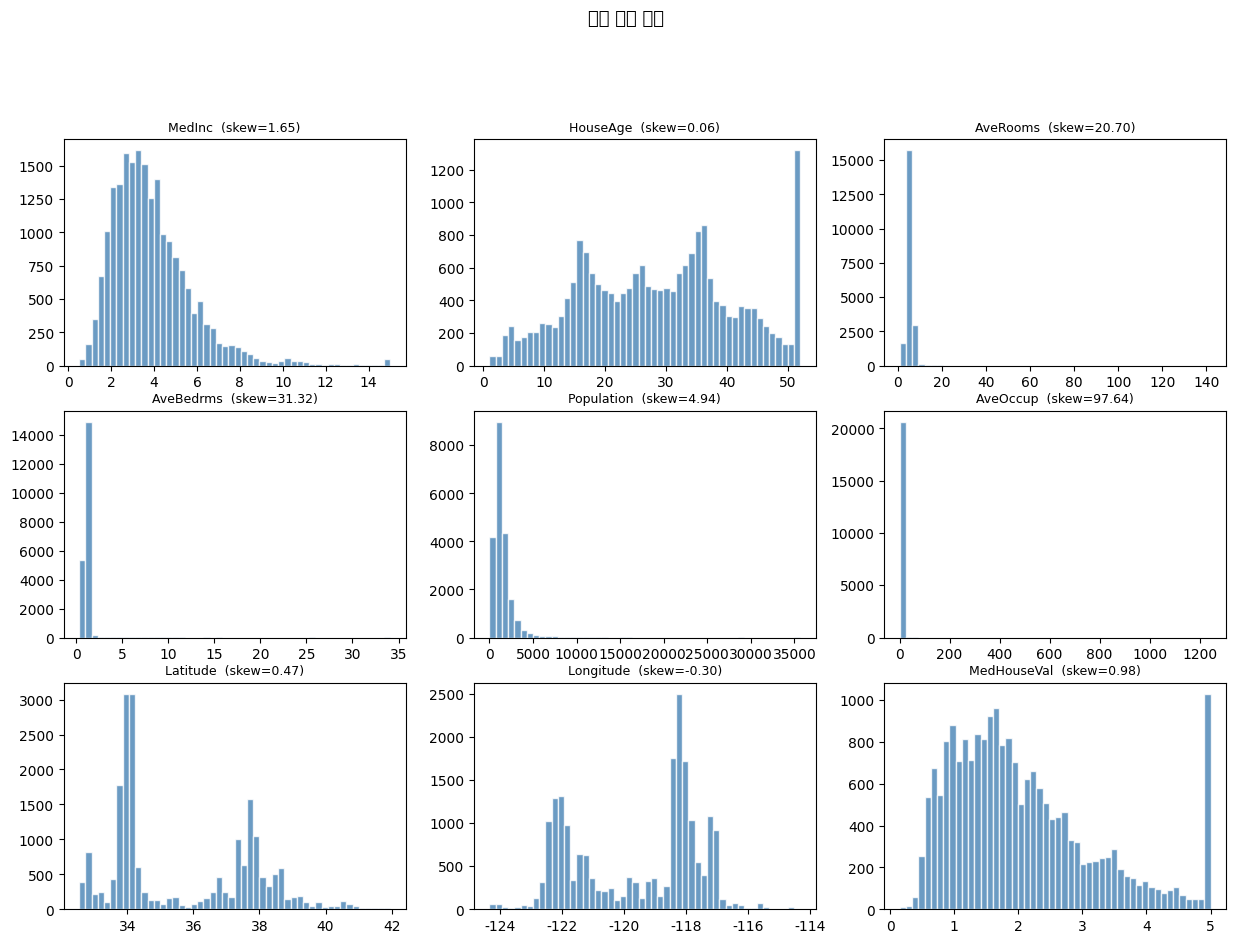

In [83]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()
for i, col in enumerate(df_raw.columns):
    axes[i].hist(df_raw[col], bins=50, color='steelblue', edgecolor='white', alpha=0.8)
    axes[i].set_title(f'{col}  (skew={df_raw[col].skew():.2f})', fontsize=9)
plt.suptitle('원본 변수 분포', fontsize=13, y=1.01)
plt.show()

>기초통계 및 그래프를 확인한 결과 MedHouseVal은 최대값이 5에서 막혀있으며 히스토그램에서 5.0 근처에만 갑자기 1000개가 넘게 몰려있는 것을 확인할 수 있다. 이는 실제로는 4.8과 7.0처럼 완전히 다른집인데 같은 5.0으로 묶고 있을 가능성이 있다. 따라서 왜곡된 5.0 데이터를 제거하면 자연스러운 분포가 나오고 모델 패턴 또한 제대로 학습할 수 있게 될것이다.)

>기초통계 및 그래프를 확인한 결과 MedInc, AveRooms, AveBedrms, AveOccup, Population 변수가 왜도가 1이 넘으며 X축이 비정상적으로 길게늘어진 것을 확인 할 수 있다. 따라서 이 변수들에 한해서 극단적인 이상치를 제거하도록 하겠다.

>왜도가 |1|을 초하면면 분포가 한쪽으로 치우쳐 있는 것을 의미한다. 선형 회귀에서는 최소제곱법을 사용하기 때문에 이상치들이 오차의 제곱으로 반영되어 회귀선 전체가 이상치 방향으로 끌려간다. 결과적으로 일반 데이터에 대한 예측 성능이 떨어지기 때문에 이를 로그변환으로 완화시키도록 하겠다
.

#### 1-2 상관관계 분석

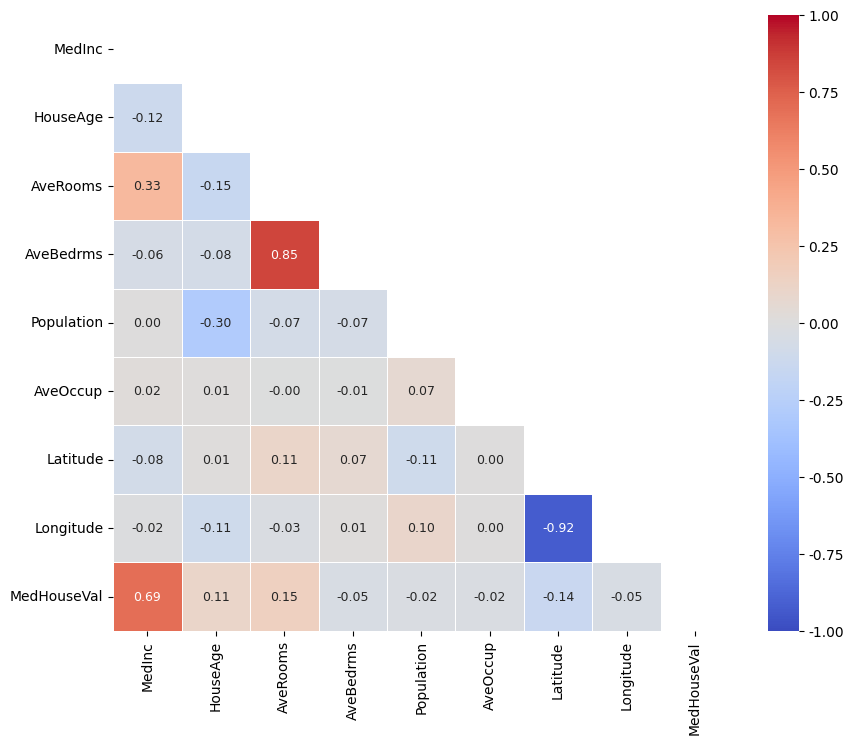

MedHouseVal    1.000
MedInc         0.688
AveRooms       0.152
Latitude       0.144
HouseAge       0.106
AveBedrms      0.047
Longitude      0.046
Population     0.025
AveOccup       0.024
Name: MedHouseVal, dtype: float64


In [86]:
plt.figure(figsize=(10, 8))
corr = df_raw.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            mask=mask, vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, annot_kws={'size': 9})
plt.show()

print(corr['MedHouseVal'].abs().sort_values(ascending=False).round(3))

> 상관관계 분석결과 가장큰 상관관계 Medlnc 0.688이다. 전체적으로 변수와 target간의 상관관계가 크지 않은 것을 알 수 있다. 이를 보안하기 위해서 원본 변수만으로는 알기 어려운 주거의 질과 밀집도를 파생변수로 생성하여 상관계수를 높이도록 하겠다.

### 2. 전처리

* 위에서 말해던 이상치 제거, capping 제거 및 왜도 로그 변환을 포함해서 이상치 제거, 파생변수 생성, 다중공선성 분석을 통해 최종 Feature을 선택하고자 한다. 

#### 2-1 capping 제거(MedHouseVal >= 5.0 제거)

In [91]:
df = df_raw[df_raw['MedHouseVal'] < 5.0].copy()
print(f'제거 전: {len(df_raw)}행 → 제거 후: {len(df)}행 ({len(df_raw)-len(df)}건 제거)')

제거 전: 20640행 → 제거 후: 19648행 (992건 제거)


#### 2-2 IQR × 3.0 기준 극단 이상치 제거 

In [93]:
iqr_cols = ['AveRooms', 'AveBedrms', 'AveOccup', 'Population']
for col in iqr_cols:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    df = df[(df[col] >= Q1 - 3*IQR) & (df[col] <= Q3 + 3*IQR)]

print(f'이상치 제거 후: {len(df):,}행  (제거: {len(df_raw)-len(df)}건)')

이상치 제거 후: 18,451행  (제거: 2189건)


#### 2-3 파생변수 생성

>원본 변수만으로는 알 수 없는 주거질과 밀집도를 수치화하도록하겠다.

* BedroomRatio (침실/전체 방수) :  침실 비율이 낮을수록 거실, 서재 등 다양한 방이 많다는 것을 뜻한다. 이는 단순히 방 수만 보는 것보다 집의 질을 더 잘 반영하다.

* RoomsPerOccup (전체 방 수 / 거주자 수) : 1인당 방 수가 많을수록 여유있는 주거환경이므로 비싼 동네일 가능성이 높다. AveRoom만 보면 대가족이 사는 큰집인지 1인이 사는 넓은 집인지 구분이 안되는데 이 변수로 보완 가능하다.

* PopPerHousehold (인구 / 거주자 수) : 블록의 과밀도를 나타낸다. 인구가 많고 가구당 거주자도 많으면 밀집 지역인 것을 알 수 있다. 인구가 많고 가구당 거주자도 많으면 밀집 지역을 의미하므로 상대적으로 집값이 낮은 경향이 있다.


In [96]:
df = df.copy()

# 침실 비율 
df['BedroomRatio']    = df['AveBedrms'] / df['AveRooms']
# 1인당 방 수 
df['RoomsPerOccup']   = df['AveRooms'] / df['AveOccup']
# 가구당 인구 
df['PopPerHousehold'] = df['Population'] / df['AveOccup']

print(df.columns)

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal', 'BedroomRatio', 'RoomsPerOccup',
       'PopPerHousehold'],
      dtype='str')


#### 2-4 로그 변환 (왜도 완화)

In [98]:
import numpy as np

log_targets = ['MedInc', 'AveRooms', 'AveBedrms', 'AveOccup',
               'Population', 'BedroomRatio', 'RoomsPerOccup', 'PopPerHousehold']
for col in log_targets:
    df[f'log_{col}'] = np.log1p(df[col])
    after = df[f'log_{col}'].skew()
    print(f'변환 후:{after:>1.3f}')

print('현재 컬럼수 :',df.shape[1])

변환 후:-0.026
변환 후:-0.478
변환 후:0.451
변환 후:0.167
변환 후:-1.168
변환 후:1.670
변환 후:-0.571
변환 후:-1.068
현재 컬럼수 : 20


#### 2-5 다중공선성 분석 

In [100]:
vif_candidates = [
    'log_MedInc', 'HouseAge',
    'log_AveRooms', 'log_AveBedrms', 'log_AveOccup', 'log_Population',
    'log_BedroomRatio', 'log_RoomsPerOccup', 'log_PopPerHousehold',
    'Latitude', 'Longitude']

vif_df = pd.DataFrame()
vif_df['변수'] = vif_candidates
X_vif = df[vif_candidates].dropna()
vif_df['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])]
vif_df = vif_df.sort_values('VIF', ascending=False)

print('VIF 분석 결과:')
print(vif_df.round(2).to_string(index=False))

VIF 분석 결과:
                 변수       VIF
     log_Population 610836.85
log_PopPerHousehold 448640.74
       log_AveOccup  25895.08
       log_AveRooms  12496.95
          Longitude  11700.57
  log_RoomsPerOccup   5480.30
           Latitude   1411.12
      log_AveBedrms   1341.48
   log_BedroomRatio    489.60
         log_MedInc     58.42
           HouseAge      8.23


> VIF 10 초과 변수가 다수 존재하나, Latitude/Longitude는 지역 가격 정보를 담당하는 핵심 변수이므로 유지하였다. 대신 파생 변수와 원본 변수 간 중복 정보를 가진 log_AveBedrms, log_Population, log_AveOccup을 제거하겠다.

> log_AveBedrms 제거: log_AveRooms, log_BedroomRatio와 중복  
> log_Population제거: log_PopPerHousehold로 대체  
> log_AveOccup  제거: log_RoomsPerOccup, log_PopPerHousehold와 중복

In [102]:
FINAL_FEATURES = ['log_MedInc','HouseAge','log_AveRooms','log_BedroomRatio',  
    'log_RoomsPerOccup', 'log_PopPerHousehold', 'Latitude', 'Longitude',]

X = df[FINAL_FEATURES].copy()
y = df['MedHouseVal'].copy()

print(f'최종 선택 특성: {len(FINAL_FEATURES)}개')
print(f'데이터 크기: {X.shape[0]:,}행')

# 최종 상관관계 확인
print('\n각 특성과 MedHouseVal 상관관계:')
corr_final = df[FINAL_FEATURES + ['MedHouseVal']].corr()['MedHouseVal'].drop('MedHouseVal')
print(corr_final.sort_values(key=abs, ascending=False).round(3))

최종 선택 특성: 8개
데이터 크기: 18,451행

각 특성과 MedHouseVal 상관관계:
log_MedInc             0.636
log_RoomsPerOccup      0.392
log_AveRooms           0.262
log_BedroomRatio      -0.231
Latitude              -0.141
log_PopPerHousehold    0.100
HouseAge               0.064
Longitude             -0.047
Name: MedHouseVal, dtype: float64


>파생변수 생성 후 RoomsPerOccup(0.392)이 새롭게 높은 상관관계를 보였다. 개별 상관관계에서 큰 변화는 없었으나 이는 선형 관계만을 측정하는 상관계수의 한계이다. 실제 성능 개선 여부는 모델링 단계에서 확인 하도록 하겠다.

#### 2-6 train/test 분할 + 스케일링

In [105]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)  
X_test_sc  = scaler.transform(X_test)       

print(f'Train: {X_train.shape[0]:,}행 | Test: {X_test.shape[0]:,}행')

Train: 14,760행 | Test: 3,691행


### 3. 모델링

* 데이터 전처리 완료 후 머신러닝 회귀 문제에서 가장 많이 쓰이는 대표적인 모델인 Linear Regression, Ridge, Lasso, Decision Tree, Random Forest, Gradient Boosting, XGBoost 총 7가지 모델을 적용하여 성능을 비교하고 가장 우수한 모델을 선정하고자 한다.

* 각 모델은 GridSearchCV를 통해 최적 하이퍼파라미터를 탐색하도록 하겠다.

* 트리 기반 모델(RF, GBM, XGBoost)은 분기 기준으로 학습하기 때문에 feature 스케일의 영향을 받지 않아 스케일링 없이 원본 데이터를 사용하였다.

In [107]:
results = []

def evaluate(name, model, X_tr, X_te, y_tr, y_te):
    model.fit(X_tr, y_tr)
    tr2  = model.score(X_tr, y_tr)
    te2  = model.score(X_te, y_te)
    rmse = np.sqrt(mean_squared_error(y_te, model.predict(X_te)))
    results.append({'모델': name, 'Train R²': tr2, 'Test R²': te2, 'Test RMSE': rmse})
    print(f'\n{"-"*45}')
    print(f'  {name}')
    print(f'{"-"*45}')
    print(f'  Train R²   : {tr2:.4f}')
    print(f'  Test  R²   : {te2:.4f}')
    print(f'  Test  RMSE : {rmse:.4f}')
    return model

>7개 모델을 매번 같은 코드로 반복 작성하면 중복이 많아지니까 공통 평가 과정을 함수로 묶도록 하겠다. 

#### 3-1 Linear Regression

In [110]:
lr = evaluate('Linear Regression', LinearRegression(),
              X_train_sc, X_test_sc, y_train, y_test)


---------------------------------------------
  Linear Regression
---------------------------------------------
  Train R²   : 0.6322
  Test  R²   : 0.6234
  Test  RMSE : 0.5950


#### 3-2 Ridge Regression

In [112]:
#alpha 탐색
ridge_params = {'alpha': [0.01, 0.1, 1, 10, 100]}
ridge_gs = GridSearchCV(Ridge(), ridge_params, cv=5, scoring='r2')
ridge_gs.fit(X_train_sc, y_train)
print(f'Ridge 최적 alpha: {ridge_gs.best_params_["alpha"]}')

ridge = evaluate('Ridge Regression', Ridge(alpha=ridge_gs.best_params_['alpha']),
                 X_train_sc, X_test_sc, y_train, y_test)

Ridge 최적 alpha: 0.1

---------------------------------------------
  Ridge Regression
---------------------------------------------
  Train R²   : 0.6322
  Test  R²   : 0.6234
  Test  RMSE : 0.5950


#### 3-3 Lasso Regression

In [114]:
lasso_params = {'alpha': [0.0001, 0.001, 0.01, 0.1, 1]}
lasso_gs = GridSearchCV(Lasso(max_iter=5000), lasso_params, cv=5, scoring='r2')
lasso_gs.fit(X_train_sc, y_train)
print(f'Lasso 최적 alpha: {lasso_gs.best_params_["alpha"]}')

lasso = evaluate('Lasso Regression', Lasso(alpha=lasso_gs.best_params_['alpha'], max_iter=5000),
                 X_train_sc, X_test_sc, y_train, y_test)

# Lasso 변수 선택 결과
lasso.fit(X_train_sc, y_train)
coef_mask = lasso.coef_ != 0
print(f'\nLasso가 선택한 변수: {coef_mask.sum()}개 / {len(FINAL_FEATURES)}개')

Lasso 최적 alpha: 0.0001

---------------------------------------------
  Lasso Regression
---------------------------------------------
  Train R²   : 0.6322
  Test  R²   : 0.6234
  Test  RMSE : 0.5950

Lasso가 선택한 변수: 8개 / 8개


#### 3-4 Decision Tree Regression

In [116]:
dt_params = {'max_depth': [4, 6, 8, 10, None],
             'min_samples_leaf': [5, 10, 20]}
dt_gs = GridSearchCV(DecisionTreeRegressor(random_state=42),
                     dt_params, cv=5, scoring='r2', n_jobs=-1)
dt_gs.fit(X_train_sc, y_train) 
print(f'DT 최적 파라미터: {dt_gs.best_params_}')

dt = evaluate('Decision Tree', DecisionTreeRegressor(**dt_gs.best_params_, random_state=42),
              X_train_sc, X_test_sc, y_train, y_test)

DT 최적 파라미터: {'max_depth': None, 'min_samples_leaf': 20}

---------------------------------------------
  Decision Tree
---------------------------------------------
  Train R²   : 0.7760
  Test  R²   : 0.6802
  Test  RMSE : 0.5483


#### 3-5 Random Forest Regression

In [118]:
# Random Forest - 탐색 범위 좁게
rf_params = {'n_estimators': [100, 200],
             'max_depth': [10, 15, None],
             'min_samples_leaf': [3, 5]}
rf_gs = GridSearchCV(RandomForestRegressor(random_state=42),
                     rf_params, cv=3, scoring='r2', n_jobs=-1)
rf_gs.fit(X_train, y_train) 
print(f'RF 최적 파라미터: {rf_gs.best_params_}')

rf = evaluate('Random Forest', RandomForestRegressor(**rf_gs.best_params_, random_state=42),
              X_train, X_test, y_train, y_test)

RF 최적 파라미터: {'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 200}

---------------------------------------------
  Random Forest
---------------------------------------------
  Train R²   : 0.9360
  Test  R²   : 0.7950
  Test  RMSE : 0.4390


#### 3-6 Gradient Boosting Regression

In [120]:
gb_params = {'n_estimators': [100, 200],
             'max_depth': [3, 4, 5],
             'learning_rate': [0.05, 0.1]}
gb_gs = GridSearchCV(GradientBoostingRegressor(random_state=42),
                     gb_params, cv=3, scoring='r2', n_jobs=-1)
gb_gs.fit(X_train, y_train)
print(f'GBM 최적 파라미터: {gb_gs.best_params_}')

gb = evaluate('Gradient Boosting', GradientBoostingRegressor(**gb_gs.best_params_, random_state=42),
              X_train, X_test, y_train, y_test)

GBM 최적 파라미터: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}

---------------------------------------------
  Gradient Boosting
---------------------------------------------
  Train R²   : 0.8917
  Test  R²   : 0.8287
  Test  RMSE : 0.4013


#### 3-7 XGBoost Regression

In [122]:
xgb_params = {'n_estimators': [100, 200],
              'max_depth': [4, 6],
              'learning_rate': [0.05, 0.1],
              'subsample': [0.8, 1.0],
              'colsample_bytree': [0.8, 1.0]}
xgb_gs = GridSearchCV(
    xgb.XGBRegressor(random_state=42, verbosity=0, eval_metric='rmse'),
    xgb_params, cv=3, scoring='r2', n_jobs=-1
)
xgb_gs.fit(X_train, y_train)
print(f'XGBoost 최적 파라미터: {xgb_gs.best_params_}')

xgb_model = evaluate('XGBoost',
    xgb.XGBRegressor(**xgb_gs.best_params_, random_state=42, verbosity=0, eval_metric='rmse'),
    X_train, X_test, y_train, y_test)

XGBoost 최적 파라미터: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 200, 'subsample': 0.8}

---------------------------------------------
  XGBoost
---------------------------------------------
  Train R²   : 0.9184
  Test  R²   : 0.8308
  Test  RMSE : 0.3989


### 4. 결과분석

In [124]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('Test R²', ascending=False)
results_df[['Train R²','Test R²','Test RMSE']] = \
    results_df[['Train R²','Test R²','Test RMSE']].round(4)
print('-' * 55)
print('모델 성능 최종 비교')
print('-' * 55)
print(results_df.to_string(index=False))

-------------------------------------------------------
모델 성능 최종 비교
-------------------------------------------------------
               모델  Train R²  Test R²  Test RMSE
          XGBoost    0.9184   0.8308     0.3989
Gradient Boosting    0.8917   0.8287     0.4013
    Random Forest    0.9360   0.7950     0.4390
    Decision Tree    0.7760   0.6802     0.5483
 Lasso Regression    0.6322   0.6234     0.5950
 Ridge Regression    0.6322   0.6234     0.5950
Linear Regression    0.6322   0.6234     0.5950


>모델 성능 비교 결과, 7가지 모델 중 XGBoost가 Train R² 0.9184, Test R² 0.8308, RMSE 0.3989로 가장 우수한 성능을 보였으며 목표인 R² 0.8을 달성하였다.

>선형 모델(Linear Regression, Ridge, Lasso)은 세 모델 모두 Train R² 0.6322, Test R² 0.6234로 동일한 수준에 머물렀다. 이는 선형 관계만 포착하는 모델의 한계로 주택 가격과 변수 간의 비선형 관계를 설명하지 못한 것으로 판단된다.

>Decision Tree는 Test R² 0.6802로 선형 모델보다 개선되었으나 Train R²(0.7760)과 Test R²(0.6802)의 차이가 있어 과적합이 의심된다.

>Random Forest는 Test R² 0.7950으로 준수한 성능을 보였으나 Train R²(0.9360)과 Test R²의 차이가 0.141로 과적합이 가장 심하게 나타났다.

>Gradient Boosting과 XGBoost는 각각 Test R² 0.8287, 0.8308로 목표를 달성하였으며 Train-Test R² 차이도 각각 0.063, 0.088로 안정적인 일반화 성능을 보였다.

>따라서 최종 모델로 XGBoost를 선정한다.

  XGBoost 최종 모델 성능 검증
  R²   : 0.8308
  RMSE : 0.3989  (억 단위)
  MAE  : 0.2729  (억 단위)


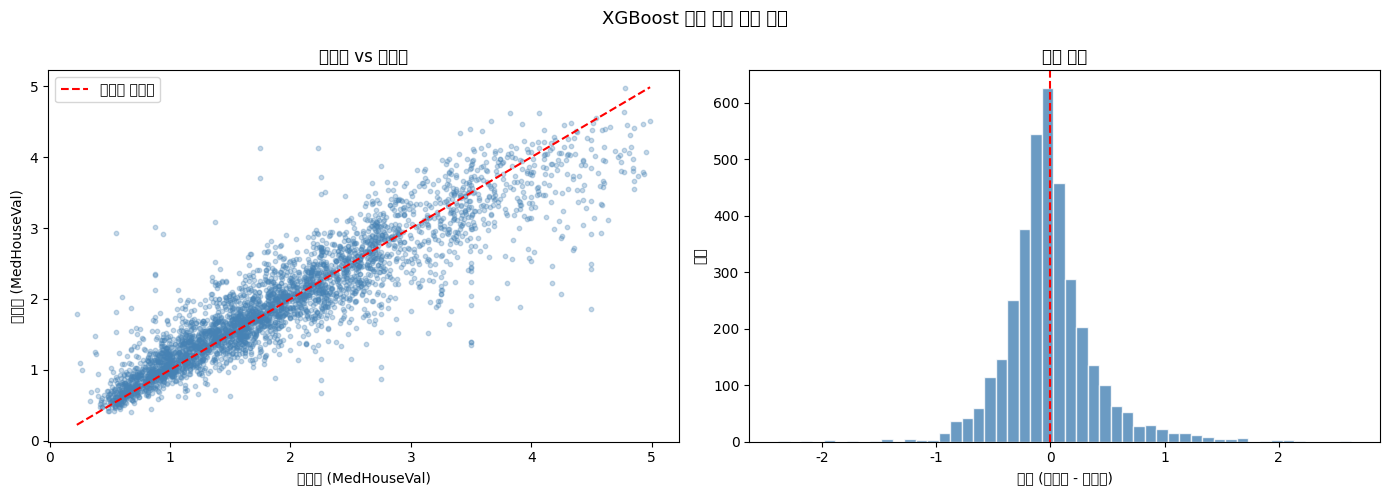


[샘플 10개 예측 결과]
  실제값   예측값     오차
2.104 2.037  0.067
2.201 2.391 -0.190
1.271 1.691 -0.420
0.404 0.941 -0.537
2.074 2.571 -0.497
2.380 2.080  0.300
2.988 3.263 -0.275
2.475 1.900  0.575
2.015 1.892  0.123
2.589 2.664 -0.075


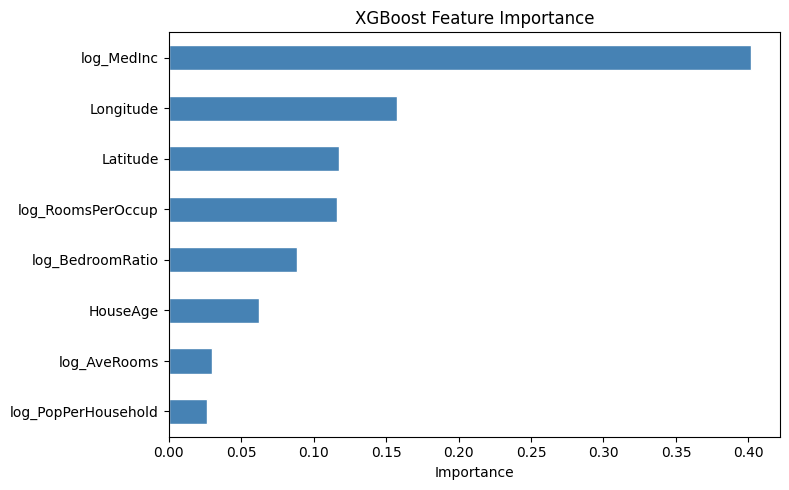


[Feature Importance 순위]
log_MedInc             0.4017
Longitude              0.1578
Latitude               0.1174
log_RoomsPerOccup      0.1161
log_BedroomRatio       0.0883
HouseAge               0.0626
log_AveRooms           0.0298
log_PopPerHousehold    0.0263


In [163]:
### 5. XGBoost 모델 검증 — 예측값 vs 실제값 분석

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ── 1. 최적 XGBoost 모델로 예측 ──────────────────────────────
best_model = xgb_gs.best_estimator_
y_pred = best_model.predict(X_test)

# ── 2. 성능 지표 출력 ────────────────────────────────────────
r2   = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae  = mean_absolute_error(y_test, y_pred)

print('=' * 45)
print('  XGBoost 최종 모델 성능 검증')
print('=' * 45)
print(f'  R²   : {r2:.4f}')
print(f'  RMSE : {rmse:.4f}  (억 단위)')
print(f'  MAE  : {mae:.4f}  (억 단위)')
print('=' * 45)

# ── 3. 실제값 vs 예측값 산점도 ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 산점도
axes[0].scatter(y_test, y_pred, alpha=0.3, color='steelblue', s=10)
axes[0].plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()],
             'r--', linewidth=1.5, label='완벽한 예측선')
axes[0].set_xlabel('실제값 (MedHouseVal)')
axes[0].set_ylabel('예측값 (MedHouseVal)')
axes[0].set_title('실제값 vs 예측값')
axes[0].legend()

# 잔차 분포
residuals = y_test - y_pred
axes[1].hist(residuals, bins=50, color='steelblue', edgecolor='white', alpha=0.8)
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_xlabel('잔차 (실제값 - 예측값)')
axes[1].set_ylabel('빈도')
axes[1].set_title('잔차 분포')

plt.suptitle('XGBoost 모델 예측 성능 검증', fontsize=13)
plt.tight_layout()
plt.show()

# ── 4. 샘플 10개 실제값 vs 예측값 직접 비교 ─────────────────
comparison = pd.DataFrame({
    '실제값': y_test.values[:10].round(3),
    '예측값': y_pred[:10].round(3),
    '오차':   (y_test.values[:10] - y_pred[:10]).round(3)
})
print('\n[샘플 10개 예측 결과]')
print(comparison.to_string(index=False))

# ── 5. Feature Importance ────────────────────────────────────
importances = pd.Series(
    best_model.feature_importances_,
    index=FINAL_FEATURES
).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importances.plot(kind='barh', color='steelblue', edgecolor='white')
plt.title('XGBoost Feature Importance')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print('\n[Feature Importance 순위]')
print(importances.sort_values(ascending=False).round(4).to_string())

>XGBoost 모델은 R² 0.8308, RMSE 0.3989억, MAE 0.2729억으로 초기 선형 모델(R² 0.52) 대비 성능이 크게 향상되었다. 실제값 vs 예측값 산점도에서 점들이 완벽 예측선 근처에 촘촘하게 분포하고 있어 전반적으로 주택 가격 패턴을 잘 학습했음을 확인할 수 있다. 잔차 분포는 0을 중심으로 -1~+1 구간에 집중되어 있어 특정 방향으로 체계적으로 틀리는 편향이 없다. Feature Importance에서는 소득 수준(log_MedInc)이 가장 중요한 변수로 나타났으며, 직접 설계한 파생변수인 log_RoomsPerOccup과 log_BedroomRatio가 각각 4, 5위를 기록하여 원본 변수보다 높은 중요도를 보였다. 이는 단순 방 수보다 거주 밀도와 주거 질을 반영한 변수가 가격 예측에 더 유효함을 보여주며, 모델이 단순히 높은 수치를 달성한 것이 아니라 실제 주택 가격 결정 요인을 제대로 학습했음을 확인할 수 있다.